# Week 2 — Join & AADF Matching Audit

## tl;dr

This executable quality-audit notebook verifies deprivation join coverage before and after LSOA geography conversion, local-authority traffic coverage, and the distance distribution between collision locations and AADF count points.

## Context & Methods

### Key Assumptions

- IoD25 uses 2021 LSOA geography and is applied only to collisions in England.
- Historic LSOA codes are mapped to 2021 codes using the ONS best-fit lookup.
- AADF matching selects the nearest BNG count point among same-year candidates with the same normalised road identifier.
- Matches within 100 metres are high confidence; matches within 250 metres are retained for sensitivity analysis.
- Sources: DfT STATS19, DfT Road Traffic, MHCLG IoD25 v2, and the ONS LSOA lookup.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
plt.rcParams.update({'figure.figsize':(9,5),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.2,'font.size':10})
COLORS = {'before':'#9CA3AF','after':'#2563EB','counted':'#D97706','estimated':'#1D4ED8'}

## Data

In [2]:
context = pd.read_parquet(ROOT/'data/intermediate/int_collision_context.parquet', columns=['collision_index','collision_year','lsoa_of_accident_location','imd_decile'])
iod = pd.read_parquet(ROOT/'data/staging/stg_iod2025_lsoa.parquet', columns=['lsoa_code'])
matches = pd.read_parquet(ROOT/'data/intermediate/int_collision_aadf_match.parquet')
qa = json.loads((ROOT/'data/processed/week2_qa_summary.json').read_text())
match_qa = json.loads((ROOT/'data/processed/week2_aadf_match_summary.json').read_text())
{'collisions':len(context),'aadf_matches':len(matches),'iod_lsoas':len(iod)}

{'collisions': 513801, 'aadf_matches': 258684, 'iod_lsoas': 33755}

## Results

### 1. IoD join coverage before and after LSOA conversion

In [3]:
england = context.lsoa_of_accident_location.astype('string').str.startswith('E',na=False)
direct_codes = set(iod.lsoa_code)
join_by_year = context[england].groupby('collision_year').agg(
    rows=('collision_index','size'),
    direct=('lsoa_of_accident_location',lambda s:s.isin(direct_codes).sum()),
    after=('imd_decile',lambda s:s.notna().sum())
).reset_index()
join_by_year['before_rate'] = join_by_year.direct/join_by_year.rows
join_by_year['after_rate'] = join_by_year.after/join_by_year.rows
join_by_year[['collision_year','rows','before_rate','after_rate']]

,collision_year,rows,before_rate,after_rate
0,2021,93873,0.931514,1.0
1,2022,98546,0.931058,1.0
2,2023,96764,0.930439,1.0
3,2024,93847,1.000000,1.0
4,2025,94419,1.000000,1.0


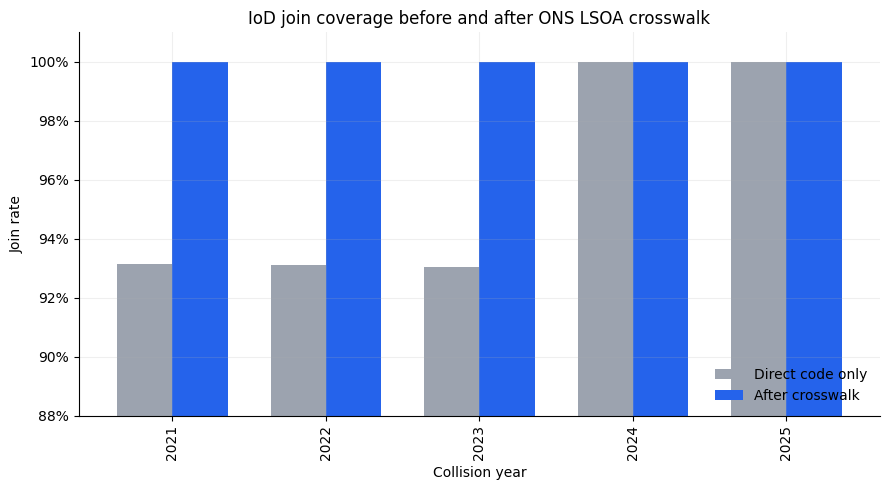

In [4]:
ax = join_by_year.plot(x='collision_year',y=['before_rate','after_rate'],kind='bar',color=[COLORS['before'],COLORS['after']],width=.72)
ax.set(title='IoD join coverage before and after ONS LSOA crosswalk',xlabel='Collision year',ylabel='Join rate',ylim=(0.88,1.01))
ax.legend(['Direct code only','After crosswalk'],frameon=False,loc='lower right')
ax.yaxis.set_major_formatter(lambda x,pos:f'{x:.0%}')
plt.tight_layout(); plt.show()

### 2. Nearest AADF match distance

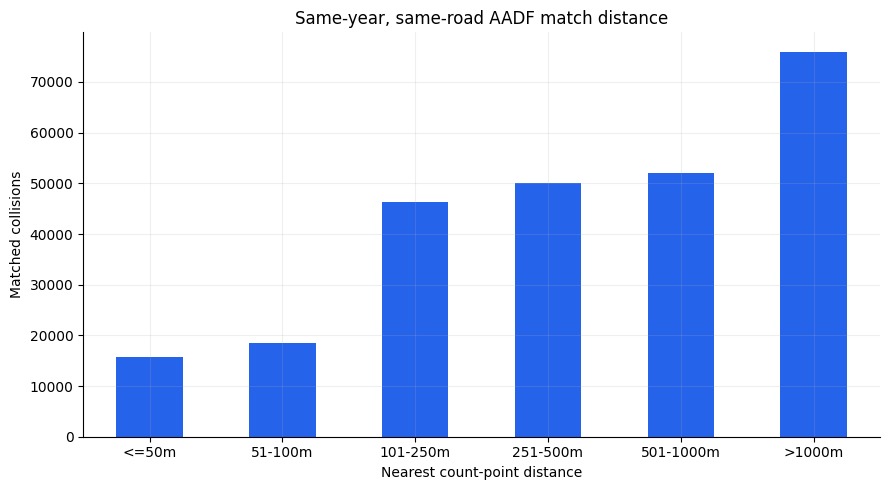

,collisions
match_band,
<=50m,15805
51-100m,18572
101-250m,46286
251-500m,50070
501-1000m,51952
>1000m,75999


In [5]:
band_order=['<=50m','51-100m','101-250m','251-500m','501-1000m','>1000m']
bands = matches.match_band.astype('string').value_counts().reindex(band_order).fillna(0).astype(int)
ax = bands.plot(kind='bar',color='#2563EB')
ax.set(title='Same-year, same-road AADF match distance',xlabel='Nearest count-point distance',ylabel='Matched collisions')
ax.tick_params(axis='x',rotation=0)
plt.tight_layout(); plt.show()
bands.to_frame('collisions')

### 3. Distance thresholds and observation methods

In [6]:
threshold_rows=[]
for threshold in [50,100,250,500]:
    subset=matches[matches.distance_m<=threshold]
    threshold_rows.append({'threshold_m':threshold,'matched':len(subset),'eligible_coverage':len(subset)/match_qa['eligible_numbered_road_collisions'],'counted_share':subset.estimation_method.eq('Counted').mean()})
thresholds=pd.DataFrame(threshold_rows)
thresholds.style.format({'eligible_coverage':'{:.1%}','counted_share':'{:.1%}'})

,threshold_m,matched,eligible_coverage,counted_share
0,50,15805,5.1%,27.1%
1,100,34377,11.2%,27.3%
2,250,80663,26.3%,27.5%
3,500,130733,42.6%,28.3%


## Takeaways

- After the ONS best-fit conversion, the England-to-IoD join reaches 100% in every year.
- Same-road AADF candidates are widely available, but nearby count points remain limited.
- The 100-metre rule is reserved for high-confidence analysis; the 250-metre rule is used for sensitivity analysis.
- Link-level results must distinguish `Counted` from `Estimated` observations, while local-authority vehicle miles remain the default exposure measure for the full analysis.